# 01 — Raw Data Analysis

**ENGE707 · Task 1**  
Explore the original labelled image dataset, inspect its quality and class distribution, and verify the saved training/validation split before model training.

## 1.1 Dataset and Environment Setup

Image identifiers are loaded as strings to retain leading zeroes in filenames such as `00001.jpg`. The dataset is read from the existing local `data` directory.

In [15]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import pandas as pd
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data"

print("Project:", ROOT)
print("Data:", DATA)

Project: C:\Users\Dibya\Dev\Kaggle
Data: C:\Users\Dibya\Dev\Kaggle\data


In [16]:
train = pd.read_csv(DATA / "train_labels.csv", dtype={"image_id": str})

display(train.head())
display(train.shape)
display(train["class"].value_counts())

,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


(63660, 2)

class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64

## 1.2 Class Distribution

The plot displays the number of training images for each of the eight classes, showing the extent of class imbalance.

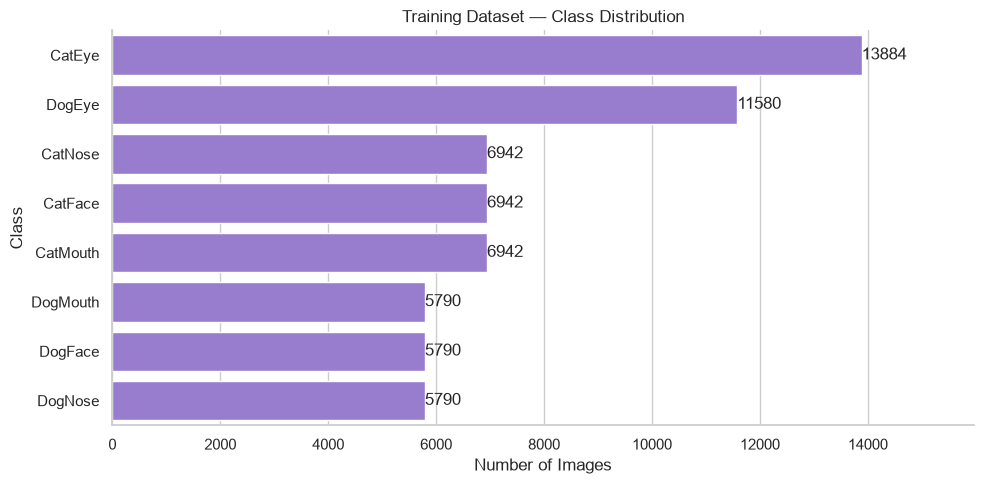

In [17]:
counts = train["class"].value_counts().rename_axis("class")
counts = counts.reset_index(name="images")

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(data=counts, x="images", y="class", color="mediumpurple", ax=ax)

for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container)

ax.set(
    title="Training Dataset — Class Distribution",
    xlabel="Number of Images",
    ylabel="Class",
)

ax.set_xlim(0, counts["images"].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

## 1.3 Visual Inspection of Sample Images

The following figures show one reproducibly sampled image per class, followed by three per class. Visual inspection helps reveal examples of small, blurry or tightly cropped inputs, but these samples alone cannot quantify image quality across the dataset.

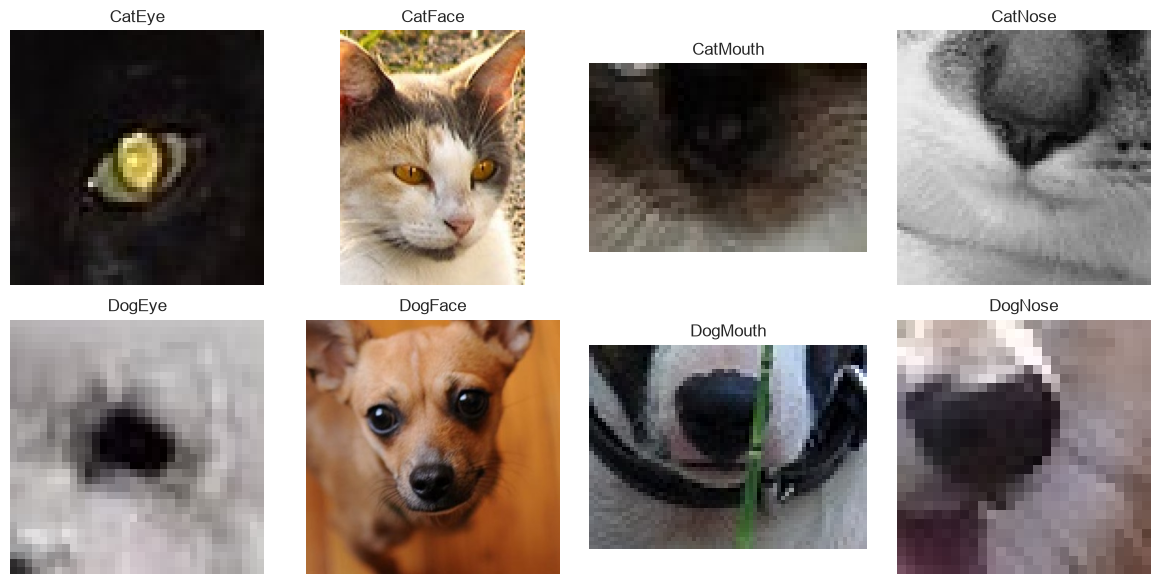

In [18]:
samples = train.groupby("class").sample(n=1, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image_path = DATA / "train" / "train" / f"{row['image_id']}.jpg"

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(row["class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

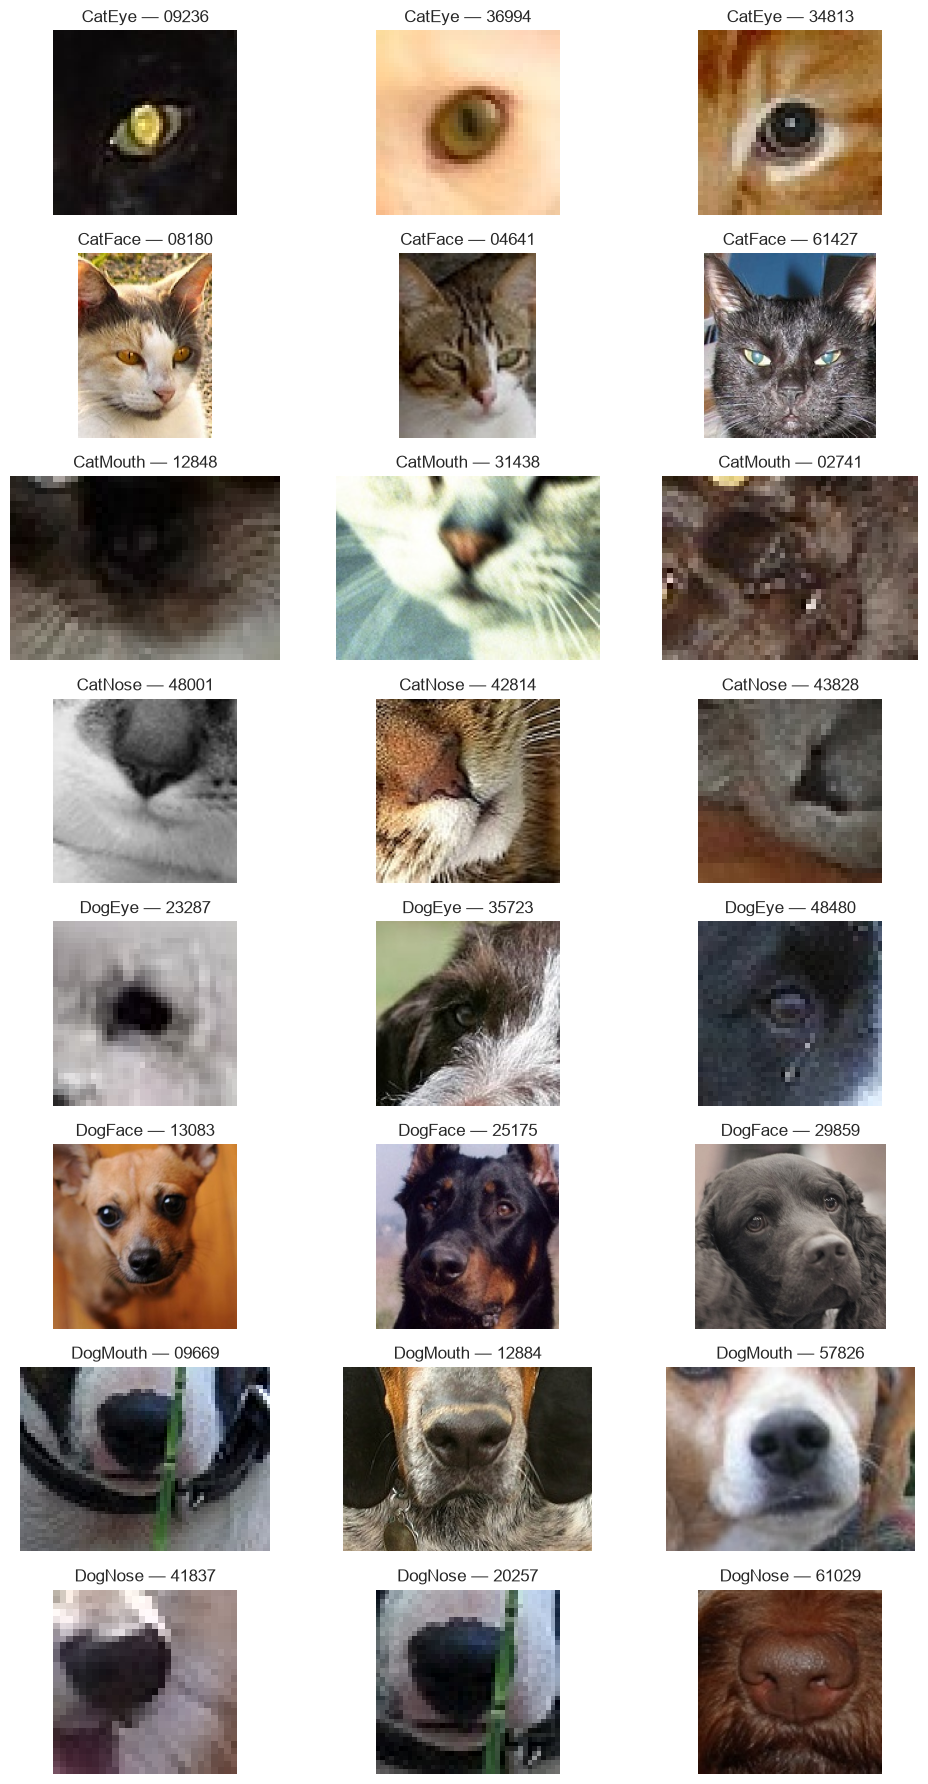

In [19]:
samples = train.groupby("class").sample(n=3, random_state=42)

fig, axes = plt.subplots(8, 3, figsize=(10, 18))

for i, (_, row) in enumerate(samples.iterrows()):
    ax = axes.flat[i]

    path = DATA / "train" / "train" / f"{row['image_id']}.jpg"

    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"{row['class']} — {row['image_id']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 1.4 Existing Dataset Audit

Load the saved audit report generated by the baseline data-checking pipeline. The dimension and duplicate fields are inspected below; these are recorded audit results, not a new full scan performed by this notebook.

In [20]:
audit_path = ROOT / "artifacts" / "audit" / "dataset_report.json"

audit = json.loads(audit_path.read_text())

print(audit.keys())

dict_keys(['labels_file', 'train_rows', 'test_rows', 'classes', 'class_distribution', 'train_files', 'test_files', 'missing_train_files', 'unexpected_train_files', 'missing_test_files', 'unexpected_test_files', 'duplicate_train_filenames', 'duplicate_test_filenames', 'overlapping_filenames_across_splits', 'train_formats', 'test_formats', 'train_dimensions', 'test_dimensions', 'corrupt_train', 'corrupt_test', 'duplicate_train_content_groups', 'duplicate_test_content_groups'])


In [21]:
fields = [
    "train_dimensions",
    "test_dimensions",
    "duplicate_train_content_groups",
    "duplicate_test_content_groups",
    "overlapping_filenames_across_splits",
]

for key in fields:
    value = audit[key]

    print(f"\n=== {key} ===")
    print("Type:", type(value).__name__)
    if isinstance(value, (dict, list)):
        print("Entries:", len(value))
        print("Preview:", str(value)[:300])
    else:
        print("Value:", value)


=== train_dimensions ===
Type: dict
Entries: 7861
Preview: {'36x36': 963, '214x157': 33, '97x97': 72, '110x110': 319, '42x42': 1050, '28x28': 606, '182x135': 41, '128x128': 261, '343x376': 1, '149x148': 1, '94x70': 136, '98x68': 115, '188x182': 1, '158x158': 76, '140x140': 166, '66x66': 831, '176x124': 65, '34x34': 978, '70x70': 665, '266x266': 9, '166x116'

=== test_dimensions ===
Type: dict
Entries: 7786
Preview: {'112x112': 36, '96x69': 1, '34x34': 69, '119x119': 12, '210x140': 6, '64x58': 5, '133x98': 11, '224x192': 4, '92x91': 10, '60x60': 343, '63x53': 10, '130x170': 9, '182x183': 3, '192x192': 32, '60x75': 3, '102x82': 36, '33x27': 1, '57x41': 1, '209x209': 3, '90x90': 162, '187x186': 3, '164x164': 80, 

=== duplicate_train_content_groups ===
Type: list
Entries: 15
Preview: [['00356.jpg', '06903.jpg'], ['03365.jpg', '42280.jpg'], ['03926.jpg', '56008.jpg'], ['04003.jpg', '46057.jpg'], ['07219.jpg', '12150.jpg'], ['13090.jpg', '63140.jpg'], ['16730.jpg', '21960.jpg'], ['25436.jp

## 1.5 Original Image Dimensions

Resolution categories use the **shorter side** of each original image. The threshold counts are cumulative; the bar-chart categories are mutually exclusive.

In [22]:
dimensions = (
    pd.Series(audit["train_dimensions"], name="count").rename_axis("size").reset_index()
)

dimensions[["width", "height"]] = (
    dimensions["size"].str.split("x", expand=True).astype(int)
)

dimensions["min_dimension"] = dimensions[["width", "height"]].min(axis=1)

for limit in [32, 64, 128, 224]:
    count = dimensions.loc[dimensions["min_dimension"] < limit, "count"].sum()

    print(f"Images with a side below {limit}px: {count:,}")

Images with a side below 32px: 4,130
Images with a side below 64px: 23,698
Images with a side below 128px: 48,063
Images with a side below 224px: 58,457


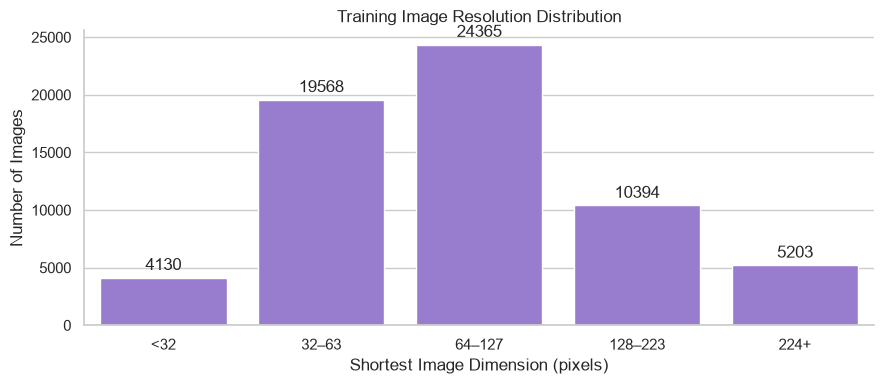

In [23]:
bins = [0, 32, 64, 128, 224, float("inf")]
resolution_labels = ["<32", "32–63", "64–127", "128–223", "224+"]

dimensions["resolution_group"] = pd.cut(
    dimensions["min_dimension"], bins=bins, labels=resolution_labels, right=False
)

resolution_counts = (
    dimensions.groupby("resolution_group", observed=True)["count"].sum().reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4))

sns.barplot(
    data=resolution_counts, x="resolution_group", y="count", color="mediumpurple", ax=ax
)

container = ax.containers[0]

if isinstance(container, BarContainer):
    ax.bar_label(container, padding=3)

ax.set(
    title="Training Image Resolution Distribution",
    xlabel="Shortest Image Dimension (pixels)",
    ylabel="Number of Images",
)

sns.despine()
plt.tight_layout()
plt.show()

## 1.6 File Integrity and Exact-Content Duplicates

Check the recorded counts of missing, unexpected and corrupted files, then inspect whether exact-content duplicate images in training have consistent labels. The `overlapping_filenames_across_splits` count refers to reused image filenames between separate training and test folders; it does **not** establish identical image content.

In [24]:
checks = [
    "missing_train_files",
    "unexpected_train_files",
    "missing_test_files",
    "unexpected_test_files",
    "corrupt_train",
    "corrupt_test",
    "duplicate_train_content_groups",
    "duplicate_test_content_groups",
]

for key in checks:
    print(f"{key}: {len(audit[key])}")

print("Overlapping filenames:", audit["overlapping_filenames_across_splits"])

missing_train_files: 0
unexpected_train_files: 0
missing_test_files: 0
unexpected_test_files: 0
corrupt_train: 0
corrupt_test: 0
duplicate_train_content_groups: 15
duplicate_test_content_groups: 62
Overlapping filenames: 29443


In [25]:
records = []

label_by_id = train.set_index("image_id")["class"]

for group in audit["duplicate_train_content_groups"]:
    ids = [Path(filename).stem for filename in group]
    group_labels = [label_by_id.loc[image_id] for image_id in ids]

    records.append(
        {
            "files": ", ".join(group),
            "classes": ", ".join(group_labels),
            "conflicting_labels": len(set(group_labels)) > 1,
        }
    )

duplicates = pd.DataFrame(records)

display(duplicates)
print("Conflicting groups:", duplicates["conflicting_labels"].sum())

,files,classes,conflicting_labels
0,"00356.jpg, 06903.jpg","CatEye, CatEye",False
1,"03365.jpg, 42280.jpg","CatEye, CatEye",False
2,"03926.jpg, 56008.jpg","CatEye, CatEye",False
3,"04003.jpg, 46057.jpg","DogEye, DogEye",False
4,"07219.jpg, 12150.jpg","CatMouth, CatMouth",False
5,"13090.jpg, 63140.jpg","CatEye, CatEye",False
6,"16730.jpg, 21960.jpg","CatEye, CatEye",False
7,"25436.jpg, 40256.jpg","CatNose, CatNose",False
8,"30201.jpg, 50179.jpg","DogEye, DogEye",False
9,"33473.jpg, 59020.jpg","CatEye, CatEye",False


Conflicting groups: 0


## 1.7 Saved Training/Validation Split Verification

Verify that the saved partitions contain no shared image IDs or known exact-content duplicate groups. This checks the existing split used by the baseline, rather than creating a second split.

In [26]:
train_split = pd.read_csv(
    ROOT / "artifacts/baseline/train_split.csv", dtype={"image_id": str}
)

val_split = pd.read_csv(
    ROOT / "artifacts/baseline/validation_split.csv", dtype={"image_id": str}
)

print("Training:", train_split.shape, train_split.columns.tolist())
print("Validation:", val_split.shape, val_split.columns.tolist())

Training: (50928, 2) ['image_id', 'class']
Validation: (12732, 2) ['image_id', 'class']


In [27]:
train_ids = set(train_split["image_id"])
val_ids = set(val_split["image_id"])

# Check ordinary ID overlap
overlap = train_ids & val_ids

# Check whether identical images were split apart
leaked_groups = []

for group in audit["duplicate_train_content_groups"]:
    ids = [Path(filename).stem for filename in group]

    in_train = any(id in train_ids for id in ids)
    in_val = any(id in val_ids for id in ids)

    if in_train and in_val:
        leaked_groups.append(group)

print("Overlapping image IDs:", len(overlap))
print("Duplicate groups crossing splits:", len(leaked_groups))
print("Images accounted for:", len(train_ids | val_ids))

Overlapping image IDs: 0
Duplicate groups crossing splits: 0
Images accounted for: 63660


## 1.8 Findings and Limitations

- The original training dataset contains **63,660 labelled images** across **eight classes**.
- Class frequencies are uneven: **CatEye** has the most samples (13,884), while the three least frequent dog-feature classes each have 5,790.
- Original image dimensions vary substantially. **58,457 images (approximately 91.8%)** have at least one side shorter than 224 pixels.
- The sampled images exhibit variations in clarity, lighting and cropping. These examples are illustrative and do not establish the prevalence of each image-quality issue.
- The saved dataset audit reported **no missing, unexpected or corrupted image files**.
- It identified **15 exact-content duplicate groups in training** and **62 in test**. The training duplicate groups have no conflicting class labels.
- The saved 80/20 training/validation split has **no overlapping image IDs** and no known exact-content duplicate groups crossing partitions.

**Limitations:** Exact-content duplicate checks do not identify every visually related image or different crop of the same source photograph. Many original images are small, so resizing cannot recover absent visual detail. Further analysis would be needed to assess near-duplicate leakage or label ambiguity.

## Reference — Raw Data Analysis Checklist

Retained as a quick troubleshooting reference for this notebook.

- [x] Class distribution and imbalance
- [x] Representative images from all eight classes
- [x] Original image resolution distribution
- [x] Missing and corrupted image checks
- [x] Exact-duplicate image and label consistency checks
- [x] Training/validation ID and known exact-duplicate leakage checks